# Análise dos resultados do benchmark (Cap. 6 do TCC)

Gera **todas as figuras e tabelas** de resultados do TCC a partir das saídas do benchmark:

| Seção | Figuras (`escrita tcc/imagens/`) | Tabelas (`escrita tcc/tabelas/`) |
|---|---|---|
| 1. Execução sem GPU | `eda_real_tempo.png`, `eda_real_resolucao.png`, `eda_real_ram.png` | `extracao_resumo.tex` |
| 2. Qualidade (CER/WER) | `resultados_cer_paginas.png`, `resultados_heatmap.png`, `resultados_dificuldade.png`, `resultados_cer_custo.png` | `avaliacao_resumo.tex`* |
| 3. Padrões de erro | `resultados_fidelidade.png` | `erros_resumo.tex` |

\* gerada por `benchmark/avaliar.py`, que calcula o CER/WER; este notebook só lê o resultado.

**Ordem de execução**, a partir da raiz do repositório:

```bash
python benchmark/extrair.py            # roda os modelos (horas; só uma vez)
python benchmark/avaliar.py            # CER/WER contra a regra ouro (segundos)
jupyter nbconvert --to notebook --execute --inplace eda/analise_resultados.ipynb
```

In [1]:
import difflib
import re
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

RAIZ = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
sys.path[:0] = [str(RAIZ), str(RAIZ / "eda")]
from estilo import CORES, EIXO, GRADE, MUDO, TINTA, TINTA_2, formatador_br, num  # noqa: E402
from benchmark.avaliar import LIMIAR_FALHA, normalizar  # noqa: E402

AVALIACAO = RAIZ / "data" / "results" / "avaliacao"
EXTRACAO = RAIZ / "data" / "results" / "extracao"
REGRA_OURO = RAIZ / "data" / "corpus" / "regra_ouro"
FIGURAS = RAIZ / "escrita tcc" / "imagens"
TABELAS = RAIZ / "escrita tcc" / "tabelas"

# Modelos apresentados no TCC: nome, categoria (define a cor) e se rodou em GPU na nuvem.
MODELOS = {
    "abbyy": ("ABBYY FineReader", "Clássico", False),
    "tesseract": ("Tesseract", "Clássico", False),
    "paddleocr": ("PaddleOCR", "Clássico", False),
    "doctr": ("DocTR", "Clássico", False),
    "easyocr": ("EasyOCR", "Clássico", False),
    "glm-ocr": ("GLM-OCR", "VLM local", False),
    "qwen-7b": ("Qwen2.5-VL 7B", "VLM local", True),
    "gemma4-e4b": ("Gemma 4 E4B", "VLM local", True),
    "deepseek-ocr": ("DeepSeek-OCR", "VLM local", True),
    "llamaparse-free": ("LlamaParse (básico)", "Serviço via API", False),
    "claude": ("Claude Opus 5.5", "Serviço via API", False),
}
RESSALVA = {"claude"}  # regra ouro derivada da transcrição deste modelo (Cap. 4)
DIFICULDADES = ["Fácil", "Médio", "Difícil"]
MARCADORES = {"Fácil": "o", "Médio": "s", "Difícil": "^"}
TONS = {"Fácil": "#b5b4ad", "Médio": "#6f6e69", "Difícil": TINTA}
OBRAS = {"heloiza": "Heloíza", "culto_mulher_v1": "Culto v1", "culto_mulher_v2": "Culto v2",
         "amante_militar": "Amante", "feliz_independente": "Feliz Indep."}
# Resolução nativa das digitalizações e páginas de cada obra no corpus completo.
PPI = {"heloiza": 150, "culto_mulher_v1": 137, "culto_mulher_v2": 150,
       "amante_militar": 300, "feliz_independente": 300}
PAGINAS_OBRA = {"heloiza": 144, "culto_mulher_v1": 254, "culto_mulher_v2": 219,
                "amante_militar": 110, "feliz_independente": 1043}
RAM_TOTAL_GB = 7.5  # equipamento do trabalho (Tabela tab:ambiente)


def nome(m):
    rotulo, _, gpu = MODELOS[m]
    return rotulo + (" (GPU)" if gpu else "") + (" †" if m in RESSALVA else "")


def salvar(fig, arquivo):
    fig.savefig(FIGURAS / arquivo, bbox_inches="tight")
    plt.show()
    print("salvo:", arquivo)

## Dados

In [2]:
manifesto = pd.read_csv(REGRA_OURO / "manifest.csv", dtype={"pagina": str})
por_pagina = pd.read_csv(AVALIACAO / "por_pagina.csv", dtype={"pagina": str})
por_pagina = por_pagina[por_pagina["modelo"].isin(MODELOS)].copy()
por_pagina["rotulo"] = por_pagina["modelo"].map(nome)
por_pagina["categoria"] = por_pagina["modelo"].map(lambda m: MODELOS[m][1])
resumo = pd.read_csv(AVALIACAO / "resumo_modelos.csv")
resumo = resumo[resumo["modelo"].isin(MODELOS)]

# Execução: metricas.csv = equipamento do trabalho (CPU); metricas_gpu.csv = nuvem (GPU T4).
cpu = pd.read_csv(EXTRACAO / "metricas.csv", dtype={"pagina": str})
cpu = cpu[cpu["modelo"].isin(MODELOS)].drop_duplicates(["modelo", "obra", "pagina"], keep="last")
cpu["resolucao"] = cpu["obra"].map(lambda o: "300 ppi" if PPI[o] == 300 else "~150 ppi")
cpu["categoria"] = cpu["modelo"].map(lambda m: MODELOS[m][1])
gpu = pd.read_csv(EXTRACAO / "metricas_gpu.csv", dtype={"pagina": str})
gpu = gpu[gpu["modelo"].isin(MODELOS)].drop_duplicates(["modelo", "obra", "pagina"], keep="last")

print(f"{por_pagina['modelo'].nunique()} modelos avaliados, {len(manifesto)} páginas")
resumo[["nome", "cer", "wer", "cer_mediana", "falhas", "cer_sem_falhas", "wer_sem_falhas"]].round(4)

11 modelos avaliados, 20 páginas


,nome,cer,wer,cer_mediana,falhas,cer_sem_falhas,wer_sem_falhas
0,Claude Opus 5.5,0.0023,0.0068,0.0004,0,0.0023,0.0068
1,Qwen2.5-VL 7B,0.0156,0.0543,0.0157,0,0.0156,0.0543
2,Gemma 4 E4B,0.0206,0.0869,0.0182,0,0.0206,0.0869
3,GLM-OCR,0.0576,0.0846,0.0064,1,0.0077,0.0347
4,LlamaParse (básico),0.0584,0.1316,0.0258,0,0.0584,0.1316
5,DocTR,0.0858,0.2846,0.0727,0,0.0858,0.2846
6,ABBYY FineReader,0.1309,0.3983,0.0778,1,0.0944,0.3674
7,EasyOCR,0.1476,0.4615,0.1496,0,0.1476,0.4615
8,Tesseract,0.1809,0.4581,0.1730,0,0.1809,0.4581
9,PaddleOCR,0.2018,0.3946,0.1414,2,0.1546,0.3646


## 1. Execução no equipamento sem GPU

Tempo e memória medidos por `benchmark/extrair.py` no notebook do trabalho (CPU, 7,5 GB de RAM). Só entram os
modelos que rodaram nesse equipamento; os executados em GPU na nuvem estão na seção 1.4.

In [3]:
# 1.1 Tabela-resumo, com projeção do tempo para o corpus completo (média de cada
# resolução, ponderada pelo número de páginas do corpus em cada uma).
pag150 = sum(v for o, v in PAGINAS_OBRA.items() if PPI[o] != 300)
pag300 = sum(v for o, v in PAGINAS_OBRA.items() if PPI[o] == 300)
linhas, tab = [], []
for modelo in cpu.groupby("modelo")["tempo_s"].median().sort_values().index:
    d = cpu[cpu["modelo"] == modelo]
    t150 = d.loc[d["resolucao"] == "~150 ppi", "tempo_s"].mean()
    t300 = d.loc[d["resolucao"] == "300 ppi", "tempo_s"].mean()
    horas = (pag150 * t150 + pag300 * t300) / 3600
    proj = f"{num(horas * 60, 0)} min" if horas < 1 else (f"{num(horas)} h" if horas < 48 else f"{num(horas / 24)} dias")
    tab.append({"modelo": MODELOS[modelo][0], "paginas": len(d), "mediana_s": d["tempo_s"].median(),
                "min_s": d["tempo_s"].min(), "max_s": d["tempo_s"].max(), "ram_pico_mb": d["ram_pico_mb"].max(),
                "projecao": proj})
    linhas.append(f"{MODELOS[modelo][0]} & {len(d)} & {num(d['tempo_s'].median())} & "
                  f"{num(d['tempo_s'].min())}--{num(d['tempo_s'].max())} & {num(d['ram_pico_mb'].max(), 0)} & {proj} \\\\")
tex = r'''% Gerado automaticamente por eda/analise_resultados.ipynb -- não editar à mão.
\begin{table}[H]
\centering
\caption{Execução dos modelos sobre as 20 páginas da amostra, no ambiente da
Tabela~\ref{tab:ambiente}.}
\label{tab:extracao_resumo}
\renewcommand{\arraystretch}{1.25}
{\small
\begin{tabular}{l r r r r r}
\hline
& & \multicolumn{2}{c}{\textbf{Tempo por página (s)}} & \textbf{RAM} & \textbf{Projeção} \\
\textbf{Modelo} & \textbf{Págs.} & \textbf{Mediana} & \textbf{Mín.--máx.} & \textbf{pico (MB)} & \textbf{corpus} \\
\hline
''' + "\n".join(linhas) + r'''
\hline
\end{tabular}
}
\fonte{Elaborado pelo autor.}
\end{table}
'''
(TABELAS / "extracao_resumo.tex").write_text(tex, encoding="utf-8")
pd.DataFrame(tab)

,modelo,paginas,mediana_s,min_s,max_s,ram_pico_mb,projecao
0,PaddleOCR,20,1.50,0.6,2.6,2121,47 min
1,Tesseract,20,1.75,1.1,4.2,197,55 min
2,DocTR,20,7.00,4.2,12.9,2680,"3,5 h"
3,LlamaParse (básico),20,8.35,4.8,16.6,181,"4,0 h"
4,EasyOCR,20,10.10,6.7,16.1,3827,"5,8 h"
5,GLM-OCR,20,121.75,81.9,303.9,3044,"4,0 dias"


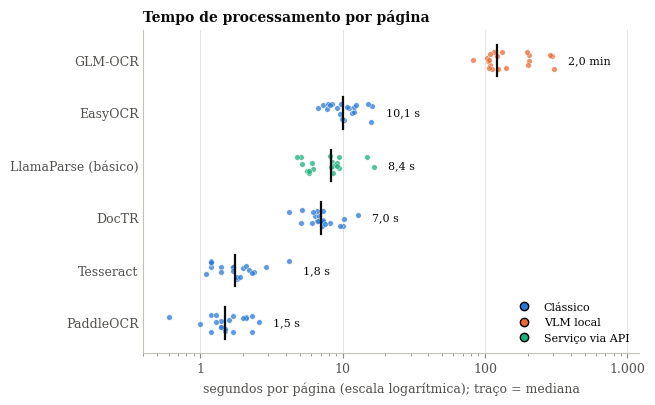

salvo: eda_real_tempo.png


In [4]:
# 1.2 Tempo por página: cada ponto é uma página; o traço marca a mediana.
ordem = cpu.groupby("modelo")["tempo_s"].median().sort_values().index
fig, ax = plt.subplots(figsize=(6.4, 0.5 * len(ordem) + 1.2))
rng = np.random.default_rng(0)
for y, modelo in enumerate(ordem):
    d = cpu[cpu["modelo"] == modelo]
    ax.scatter(d["tempo_s"], y + rng.uniform(-0.18, 0.18, len(d)), s=16, color=CORES[MODELOS[modelo][1]],
               alpha=0.75, edgecolor="white", linewidth=0.4, zorder=2)
    med = d["tempo_s"].median()
    ax.plot([med, med], [y - 0.3, y + 0.3], color=TINTA, linewidth=1.6, zorder=3)
    ax.text(d["tempo_s"].max() * 1.25, y, f"{num(med)} s" if med < 60 else f"{num(med / 60)} min",
            va="center", fontsize=8, color=TINTA)
ax.set_yticks(range(len(ordem)), [MODELOS[m][0] for m in ordem])
ax.tick_params(axis="y", length=0)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(formatador_br())
ax.set_xlim(0.4, cpu["tempo_s"].max() * 4)
ax.set_xlabel("segundos por página (escala logarítmica); traço = mediana")
ax.set_title("Tempo de processamento por página")
ax.xaxis.grid(True, color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Line2D([], [], marker="o", color="none", markerfacecolor=CORES[c], markersize=6, label=c)
                   for c in CORES if c in set(cpu["categoria"])], loc="lower right", fontsize=8)
salvar(fig, "eda_real_tempo.png")

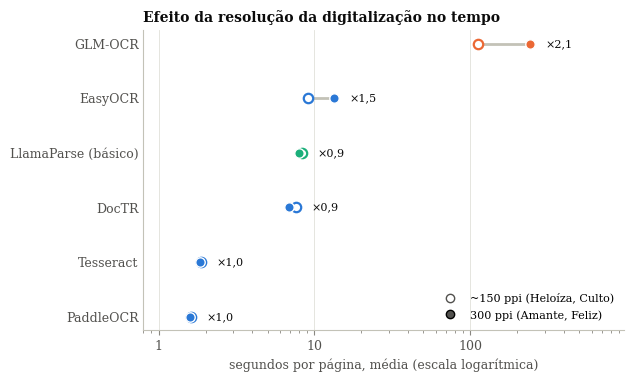

salvo: eda_real_resolucao.png


modelo
paddleocr          0.98
tesseract          0.98
doctr              0.90
llamaparse-free    0.95
easyocr            1.48
glm-ocr            2.15
Name: razão 300/150 ppi, dtype: float64

In [5]:
# 1.3a Efeito da resolução da digitalização no tempo médio por página.
t = cpu.groupby(["modelo", "resolucao"])["tempo_s"].mean().unstack().sort_values("~150 ppi")
fig, ax = plt.subplots(figsize=(6.2, 0.45 * len(t) + 1.2))
for y, (modelo, r) in enumerate(t.iterrows()):
    cor = CORES[MODELOS[modelo][1]]
    a, b = r["~150 ppi"], r["300 ppi"]
    ax.plot([a, b], [y, y], color=EIXO, linewidth=2, zorder=1)
    ax.scatter([b], [y], s=46, color=cor, edgecolor="white", linewidth=1, zorder=3)
    ax.scatter([a], [y], s=46, facecolor="white", edgecolor=cor, linewidth=1.6, zorder=2)
    ax.text(max(a, b) * 1.25, y, f"×{num(b / a)}", va="center", fontsize=8, color=TINTA)
ax.set_yticks(range(len(t)), [MODELOS[m][0] for m in t.index])
ax.tick_params(axis="y", length=0)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(formatador_br())
ax.set_xlim(0.8, t.max().max() * 4)
ax.set_xlabel("segundos por página, média (escala logarítmica)")
ax.set_title("Efeito da resolução da digitalização no tempo")
ax.xaxis.grid(True, color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Line2D([], [], marker="o", color="none", markerfacecolor="white", markeredgecolor=TINTA_2,
                              markersize=6, label="~150 ppi (Heloíza, Culto)"),
                   plt.Line2D([], [], marker="o", color="none", markerfacecolor=TINTA_2, markersize=6,
                              label="300 ppi (Amante, Feliz)")], loc="lower right", fontsize=8)
salvar(fig, "eda_real_resolucao.png")
(t["300 ppi"] / t["~150 ppi"]).round(2).rename("razão 300/150 ppi")

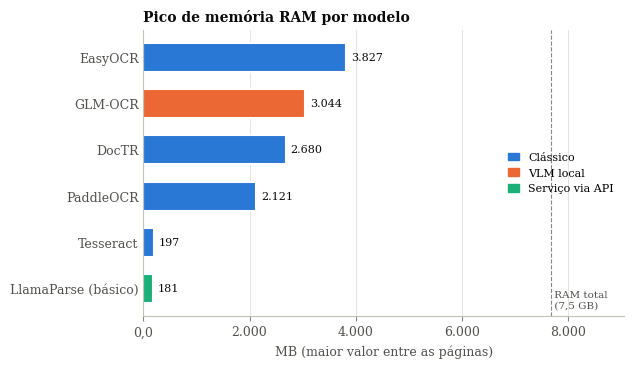

salvo: eda_real_ram.png


In [6]:
# 1.3b Pico de memória RAM por modelo, contra a RAM total do equipamento.
r = cpu.groupby("modelo")["ram_pico_mb"].max().sort_values()
total = RAM_TOTAL_GB * 1024
fig, ax = plt.subplots(figsize=(6.2, 0.42 * len(r) + 1.2))
y = np.arange(len(r))
ax.barh(y, r.values, color=[CORES[MODELOS[m][1]] for m in r.index], height=0.62, edgecolor="white", linewidth=1.5)
for yi, v in zip(y, r.values):
    ax.text(v + total * 0.012, yi, num(v, 0), va="center", fontsize=8, color=TINTA)
ax.axvline(total, color=MUDO, linestyle="--", linewidth=0.8)
ax.text(total, -0.45, f" RAM total\n ({num(RAM_TOTAL_GB)} GB)", color=TINTA_2, fontsize=7.5, va="bottom")
ax.set_yticks(y, [MODELOS[m][0] for m in r.index])
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, total * 1.18)
ax.xaxis.set_major_formatter(formatador_br())
ax.set_xlabel("MB (maior valor entre as páginas)")
ax.set_title("Pico de memória RAM por modelo")
ax.xaxis.grid(True, color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
cats = [c for c in CORES if c in set(cpu["categoria"])]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=CORES[c]) for c in cats], cats, loc="center right", fontsize=8, handlelength=1)
salvar(fig, "eda_real_ram.png")

In [7]:
# 1.4 Modelos executados em GPU na nuvem (Colab, T4): tempos só de referência,
# não comparáveis aos do equipamento do trabalho.
g = gpu.groupby("modelo")["tempo_s"].agg(["median", "min", "max"]).round(1)
g["projecao_corpus_h"] = (g["median"] * sum(PAGINAS_OBRA.values()) / 3600).round(1)
g.index = [MODELOS[m][0] for m in g.index]
g

,median,min,max,projecao_corpus_h
DeepSeek-OCR,10.9,7.9,79.6,5.4
Gemma 4 E4B,47.8,28.2,193.3,23.5
Qwen2.5-VL 7B,37.6,18.8,71.1,18.5


## 2. Qualidade do reconhecimento (CER/WER)

CER/WER calculados por `benchmark/avaliar.py` após a normalização descrita no TCC (Seção de protocolo de
avaliação). Modelos ordenados pelo CER médio. † = regra ouro derivada deste modelo; fora do ranking.

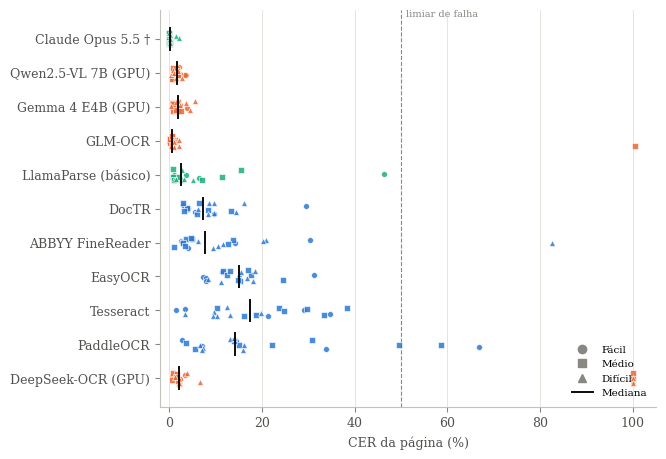

salvo: resultados_cer_paginas.png
Páginas com falha (CER >= limiar):


,rotulo,obra,pagina,cer
13,ABBYY FineReader,amante_militar,008,0.825
48,DeepSeek-OCR (GPU),culto_mulher_v1,230,1.000
52,DeepSeek-OCR (GPU),culto_mulher_v2,170,1.000
53,DeepSeek-OCR (GPU),amante_militar,008,1.000
57,DeepSeek-OCR (GPU),feliz_independente,050,1.000
58,DeepSeek-OCR (GPU),feliz_independente,200,1.000
131,GLM-OCR,culto_mulher_v2,100,1.005
164,PaddleOCR,heloiza,130,0.667
168,PaddleOCR,culto_mulher_v1,230,0.586


In [8]:
def ordem_cer():
    return por_pagina.groupby("rotulo")["cer"].mean().sort_values().index.tolist()

# 2.1 CER de cada página, por modelo; o traço marca a mediana.
ordem = ordem_cer()
fig, ax = plt.subplots(figsize=(6.4, 0.36 * len(ordem) + 1.2))
rng = np.random.default_rng(0)
for y, rot in enumerate(ordem):
    d = por_pagina[por_pagina["rotulo"] == rot]
    cor = CORES[d["categoria"].iloc[0]]
    for dif in DIFICULDADES:
        dd = d[d["dificuldade"] == dif]
        ax.scatter(100 * dd["cer"], y + rng.uniform(-0.18, 0.18, len(dd)), s=18, marker=MARCADORES[dif],
                   color=cor, alpha=0.85, edgecolors="white", linewidths=0.5, zorder=3)
    ax.plot([100 * d["cer"].median()] * 2, [y - 0.32, y + 0.32], color=TINTA, linewidth=1.4, zorder=4)
ax.axvline(100 * LIMIAR_FALHA, color=MUDO, linestyle="--", linewidth=0.8)
ax.text(100 * LIMIAR_FALHA + 1, -0.6, "limiar de falha", fontsize=7, color=MUDO, va="bottom")
ax.set_yticks(range(len(ordem)), ordem)
ax.invert_yaxis()
ax.set_xlim(-2, 105)
ax.set_xlabel("CER da página (%)")
ax.xaxis.grid(True, color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
alcas = [plt.Line2D([], [], marker=MARCADORES[d], linestyle="", color=MUDO, label=d) for d in DIFICULDADES]
alcas.append(plt.Line2D([], [], color=TINTA, linewidth=1.4, label="Mediana"))
ax.legend(handles=alcas, loc="lower right", fontsize=7.5)
salvar(fig, "resultados_cer_paginas.png")
print("Páginas com falha (CER >= limiar):")
por_pagina[por_pagina["cer"] >= LIMIAR_FALHA][["rotulo", "obra", "pagina", "cer"]].round(3)

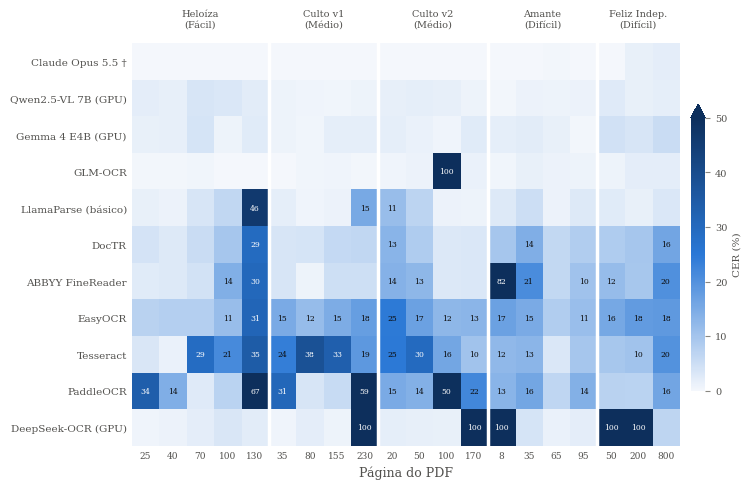

salvo: resultados_heatmap.png


In [9]:
# 2.2 CER modelo x página, colunas agrupadas por obra.
ordem = ordem_cer()
colunas = list(zip(manifesto["obra_slug"], manifesto["pagina"]))
matriz = (por_pagina.assign(chave=list(zip(por_pagina["obra"], por_pagina["pagina"])))
          .pivot(index="rotulo", columns="chave", values="cer").reindex(index=ordem, columns=colunas))
cmap = LinearSegmentedColormap.from_list("cer", ["#f4f7fc", CORES["Clássico"], "#0d2f5c"])
fig, ax = plt.subplots(figsize=(7.4, 0.33 * len(ordem) + 1.6))
im = ax.imshow(100 * matriz.values, cmap=cmap, vmin=0, vmax=50, aspect="auto")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        if v >= 0.10:
            ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=5.5,
                    color="white" if v >= 0.25 else TINTA)
ax.set_yticks(range(len(ordem)), ordem, fontsize=7.5)
ax.set_xticks(range(len(colunas)), [p.lstrip("0") for _, p in colunas], fontsize=6.5)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
inicio = 0
for obra, grupo in manifesto.groupby("obra_slug", sort=False):
    fim = inicio + len(grupo)
    if inicio:
        ax.axvline(inicio - 0.5, color="white", linewidth=2.5)
    ax.text((inicio + fim - 1) / 2, -0.9, f"{OBRAS[obra]}\n({grupo['dificuldade'].iloc[0]})",
            ha="center", va="bottom", fontsize=7, color=TINTA_2)
    inicio = fim
ax.set_xlabel("Página do PDF")
barra = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, extend="max")
barra.set_label("CER (%)", fontsize=7.5)
barra.ax.tick_params(labelsize=7)
barra.outline.set_visible(False)
salvar(fig, "resultados_heatmap.png")

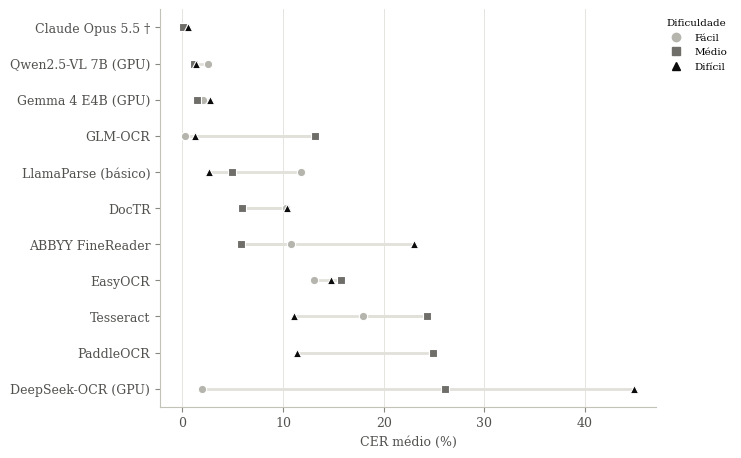

salvo: resultados_dificuldade.png


dificuldade,Fácil,Médio,Difícil
rotulo,,,
Claude Opus 5.5 †,0.0,0.1,0.6
Qwen2.5-VL 7B (GPU),2.6,1.1,1.3
Gemma 4 E4B (GPU),2.1,1.4,2.8
GLM-OCR,0.2,13.1,1.3
LlamaParse (básico),11.8,4.9,2.7
DocTR,10.2,5.9,10.4
ABBYY FineReader,10.8,5.8,23.0
EasyOCR,13.1,15.8,14.8
Tesseract,17.9,24.3,11.1


In [10]:
# 2.3 CER médio por classe de dificuldade.
ordem = ordem_cer()
medias = por_pagina.groupby(["rotulo", "dificuldade"])["cer"].mean().unstack()
fig, ax = plt.subplots(figsize=(6.4, 0.36 * len(ordem) + 1.2))
for y, rot in enumerate(ordem):
    valores = medias.loc[rot].reindex(DIFICULDADES).dropna()
    ax.plot(100 * valores.values, [y] * len(valores), color=GRADE, linewidth=2, zorder=2)
    for dif, v in valores.items():
        ax.scatter(100 * v, y, marker=MARCADORES[dif], s=36, color=TONS[dif], edgecolors="white", linewidths=0.8, zorder=3)
ax.set_yticks(range(len(ordem)), ordem)
ax.invert_yaxis()
ax.set_xlabel("CER médio (%)")
ax.xaxis.grid(True, color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Line2D([], [], marker=MARCADORES[d], linestyle="", color=TONS[d], label=d) for d in DIFICULDADES],
          loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=7.5, title="Dificuldade", title_fontsize=7.5)
salvar(fig, "resultados_dificuldade.png")
(100 * medias.reindex(index=ordem, columns=DIFICULDADES)).round(1)

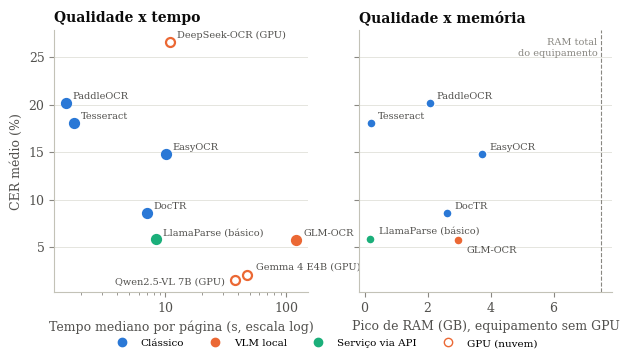

salvo: resultados_cer_custo.png


In [11]:
# 2.4 Qualidade x custo: CER médio contra tempo mediano e contra pico de RAM.
ROTULO_TEMPO = {"gemma4-e4b": (6, 4, "left"), "qwen-7b": (-7, -3, "right")}
ROTULO_RAM = {"glm-ocr": (6, -9, "left"), "llamaparse-free": (6, 4, "left")}
execucao = pd.concat([cpu, gpu])
d = (por_pagina.groupby("modelo")["cer"].mean().to_frame("cer")
     .join(execucao.groupby("modelo").agg(tempo=("tempo_s", "median"), ram=("ram_pico_mb", "max")), how="inner"))
fig, (ax_t, ax_r) = plt.subplots(1, 2, figsize=(7.2, 3.4), sharey=True)
for modelo, r in d.iterrows():
    _, categoria, em_gpu = MODELOS[modelo]
    cor = CORES[categoria]
    ax_t.scatter(r["tempo"], 100 * r["cer"], s=42, zorder=3, linewidths=1.6,
                 facecolors="white" if em_gpu else cor, edgecolors=cor)
    dx, dy, ha = ROTULO_TEMPO.get(modelo, (5, 3, "left"))
    ax_t.annotate(nome(modelo), (r["tempo"], 100 * r["cer"]), xytext=(dx, dy), ha=ha,
                  textcoords="offset points", fontsize=7, color=TINTA_2)
    if not em_gpu:  # RAM da nuvem não é comparável à do equipamento do trabalho
        ax_r.scatter(r["ram"] / 1024, 100 * r["cer"], s=42, zorder=3, color=cor, edgecolors="white", linewidths=1)
        dx, dy, ha = ROTULO_RAM.get(modelo, (5, 3, "left"))
        ax_r.annotate(nome(modelo), (r["ram"] / 1024, 100 * r["cer"]), xytext=(dx, dy), ha=ha,
                      textcoords="offset points", fontsize=7, color=TINTA_2)
ax_t.set_xscale("log")
ax_t.xaxis.set_major_formatter(formatador_br())
ax_t.set_xlabel("Tempo mediano por página (s, escala log)")
ax_t.set_ylabel("CER médio (%)")
ax_t.set_title("Qualidade x tempo")
ax_r.axvline(RAM_TOTAL_GB, color=MUDO, linewidth=0.8, linestyle="--")
ax_r.text(RAM_TOTAL_GB - 0.1, ax_r.get_ylim()[1] * 0.97, "RAM total\ndo equipamento", ha="right", va="top", fontsize=7, color=MUDO)
ax_r.set_xlabel("Pico de RAM (GB), equipamento sem GPU")
ax_r.set_title("Qualidade x memória")
for ax in (ax_t, ax_r):
    ax.yaxis.grid(True, color=GRADE, linewidth=0.6)
    ax.set_axisbelow(True)
alcas = [plt.Line2D([], [], marker="o", linestyle="", color=CORES[c], label=c) for c in CORES]
alcas.append(plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white",
                        markeredgecolor=CORES["VLM local"], label="GPU (nuvem)"))
fig.legend(handles=alcas, loc="upper center", ncol=4, fontsize=7.5, bbox_to_anchor=(0.5, 0.0))
salvar(fig, "resultados_cer_custo.png")

## 3. Padrões de erro e fidelidade ortográfica

As palavras da regra ouro e da saída de cada modelo são alinhadas (`difflib`, sobre o texto normalizado). Cada
**substituição** palavra-por-palavra é classificada em:

- **acentuação**: só os diacríticos diferem (*fôra* → *fora*);
- **pontuação** / **maiúsculas**: só pontuação ou caixa diferem;
- **s longo lido como f**: em *O Feliz Independente*, um `s` (impresso como `ſ`) virou `f` (*deste* → *defte*);
- **grafia modernizada**: a saída é a forma moderna de uma grafia antiga (*espozo* → *esposo*);
- **outros**: erros de reconhecimento propriamente ditos.

As grafias antigas são identificadas por regras (abaixo), uma aproximação: cobrem as formas pré-reforma mais
frequentes no corpus (*hum*, *elle*, *caza*, *-ão* verbal, consoantes dobradas etc.), não todas.

In [12]:
REGRAS_GRAFIA_ANTIGA = [  # (forma antiga, forma moderna) como expressões regulares
    (r"^hum$", "um"), (r"^huma(s?)$", r"uma\1"), (r"^he$", "é"),
    (r"ll", "l"), (r"ph", "f"), (r"th", "t"),
    (r"([mfptc])\1", r"\1"), (r"(?<=[aeiou])c(?=t)", ""), (r"(?<=m)p(?=t)", ""),
    (r"(av|er|ir|nh|ch)ão$", r"\1am"), (r"(?<![gs])ião$", "iam"),
    (r"ahi", "ai"), (r"^dous$", "dois"), (r"mãi", "mãe"),
    (r"(?<=o)z(?=[ao]s?$)", "s"), (r"^caz", "cas"), (r"couz", "cous"), (r"(?<=.)poz", "pos"),
    (r"^ez(?=[aeiou])", "ex"), (r"^rez", "res"), (r"fiz(?=ic)", "fis"), (r"prez(?=ent)", "pres"),
    (r"pez(?=ad)", "pes"), (r"(?<=n)z(?=[ao]$)", "s"), (r"^dez(?=[aeiou])(?!embro)", "des"),
]
ESTRANGEIRAS = {"amanza", "laffezione"}  # versos em italiano (Culto v1, p. 35)


def sem_acento(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")


def nucleo(s):
    return re.sub(r"[^\w]", "", s).lower()


def moderna(w):
    for antiga, nova in REGRAS_GRAFIA_ANTIGA:
        w = re.sub(antiga, nova, w)
    return w


def s_como_f(r, h):
    return len(r) == len(h) and r != h and all(a == b or (a == "s" and b == "f") for a, b in zip(r, h))


def classificar(obra, r, h):
    rn, hn = nucleo(r), nucleo(h)
    if obra == "feliz_independente" and s_como_f(rn, hn):
        return "s longo lido como f"
    if rn == hn:
        return "pontuação" if r.lower() != h.lower() else "maiúsculas"
    if sem_acento(rn) == sem_acento(hn):
        return "acentuação"
    if moderna(rn) != rn and sem_acento(hn) == sem_acento(moderna(rn)):
        return "grafia modernizada"
    return "outros"


substituicoes, arcaicas = [], []
for modelo in MODELOS:
    for obra, pagina in zip(manifesto["obra_slug"], manifesto["pagina"]):
        saida = EXTRACAO / modelo / obra / f"{pagina}.txt"
        if not saida.exists():
            continue
        ref = normalizar((REGRA_OURO / obra / f"{pagina}.txt").read_text(encoding="utf-8")).split()
        hip = normalizar(saida.read_text(encoding="utf-8")).split()
        for op, i1, i2, j1, j2 in difflib.SequenceMatcher(a=ref, b=hip, autojunk=False).get_opcodes():
            if op not in ("equal", "replace") or i2 - i1 != j2 - j1:
                continue
            for r, h in zip(ref[i1:i2], hip[j1:j2]):
                rn, hn = nucleo(r), nucleo(h)
                if moderna(rn) != rn and rn not in ESTRANGEIRAS:
                    arcaicas.append({"modelo": modelo, "antiga": rn, "saida": hn, "preservada": hn == rn,
                                     "modernizada": hn != rn and sem_acento(hn) == sem_acento(moderna(rn))})
                if op == "replace":
                    substituicoes.append({"modelo": modelo, "tipo": classificar(obra, r, h)})

subs = pd.crosstab(pd.DataFrame(substituicoes)["modelo"], pd.DataFrame(substituicoes)["tipo"])
arc = pd.DataFrame(arcaicas).groupby("modelo").agg(formas_antigas=("antiga", "size"),
                                                   preservadas=("preservada", "mean"),
                                                   modernizadas=("modernizada", "mean"))
erros = subs.join(arc)
erros.index = [nome(m) for m in erros.index]
erros.sort_values("modernizadas", ascending=False).round(3)

,acentuação,grafia modernizada,maiúsculas,outros,pontuação,s longo lido como f,formas_antigas,preservadas,modernizadas
Gemma 4 E4B (GPU),100,41,4,68,19,60,153,0.595,0.268
Qwen2.5-VL 7B (GPU),72,19,3,47,14,12,154,0.831,0.123
DeepSeek-OCR (GPU),66,5,3,50,19,24,88,0.773,0.057
GLM-OCR,46,5,1,38,13,9,154,0.883,0.032
EasyOCR,31,2,23,377,210,14,116,0.724,0.017
Claude Opus 5.5 †,7,0,0,4,3,1,154,0.987,0.000
ABBYY FineReader,60,0,15,181,40,43,109,0.743,0.000
DocTR,214,0,36,202,53,54,131,0.695,0.000
LlamaParse (básico),17,0,4,112,73,10,144,0.917,0.000
PaddleOCR,190,0,3,121,78,62,104,0.692,0.000


In [13]:
# Exemplos de modernização por modelo (para o texto).
a = pd.DataFrame(arcaicas)
for modelo in ["gemma4-e4b", "qwen-7b", "deepseek-ocr", "glm-ocr"]:
    ex = a[(a["modelo"] == modelo) & a["modernizada"]]
    print(f"{MODELOS[modelo][0]}: " + ", ".join(f"{x} → {y}" for (x, y), _ in
                                                  ex.groupby(["antiga", "saida"]).size().sort_values(ascending=False).head(8).items()))

Gemma 4 E4B: ezistencia → existência, espozo → esposo, rezignação → resignação, carinhozo → carinhoso, cahir → cair, carinhoza → carinhosa, cazo → caso, cazamento → casamento
Qwen2.5-VL 7B: espozo → esposo, attento → atento, cazamento → casamento, dezeja → deseja, dezesperava → desesperava, dezenvolvimento → desenvolvimento, dezesperos → desesperos, dispozições → disposições
DeepSeek-OCR: affundir → afundir, attento → atento, dezenvolvimento → desenvolvimento, ezaltação → exaltação, ezistia → existia
GLM-OCR: alli → ali, differente → diferente, mãi → mãe, occasião → ocasião, oppri → opri


In [14]:
# 3.1 Tabela de padrões de erro.
ordem_tab = [m for m in resumo.sort_values("cer")["modelo"] if m in MODELOS]
linhas = []
for m in ordem_tab:
    s = subs.loc[m] if m in subs.index else pd.Series(dtype=int)
    p = arc.loc[m]
    marca = r"$^{\dagger}$" if m in RESSALVA else ""
    linhas.append(f"{MODELOS[m][0]}{marca} & {int(s.sum())} & "
                  f"{int(s.get('acentuação', 0))} & {int(s.get('pontuação', 0))} & "
                  f"{int(s.get('s longo lido como f', 0))} & {int(s.get('grafia modernizada', 0))} & "
                  f"{num(100 * p['preservadas'])} & {num(100 * p['modernizadas'])} \\\\")
tex = r'''% Gerado automaticamente por eda/analise_resultados.ipynb -- não editar à mão.
\begin{table}[H]
\centering
\caption{Padrões de erro por modelo: substituições de palavras por tipo e tratamento
das grafias anteriores às reformas ortográficas.}
\label{tab:erros_resumo}
\renewcommand{\arraystretch}{1.25}
{\small
\begin{tabular}{l r r r r r r r}
\hline
& \multicolumn{5}{c}{\textbf{Substituições de palavras}} & \multicolumn{2}{c}{\textbf{Grafias antigas (\%)}} \\
\textbf{Modelo} & \textbf{Total} & \textbf{Acent.} & \textbf{Pont.} & \textbf{s$\to$f} & \textbf{Modern.} & \textbf{Preserv.} & \textbf{Modern.} \\
\hline
''' + "\n".join(linhas) + r'''
\hline
\end{tabular}
}
\fonte{Elaborado pelo autor.}
\par\footnotesize{s$\to$f: \textit{s} longo lido como \textit{f}, contado só em \textit{O Feliz Independente}.
Grafias antigas: palavras da regra ouro identificadas pelas regras da Seção~\ref{sec:protocolo_avaliacao},
entre as alinhadas uma a uma com a saída do modelo.}
\par\footnotesize{$^{\dagger}$ Regra ouro derivada da transcrição deste modelo.}
\end{table}
'''
(TABELAS / "erros_resumo.tex").write_text(tex, encoding="utf-8")
print("salvo: erros_resumo.tex")

salvo: erros_resumo.tex


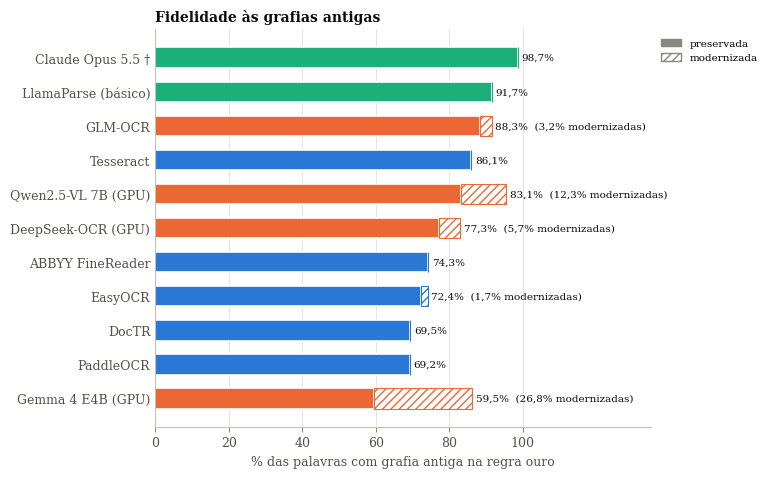

salvo: resultados_fidelidade.png


In [15]:
# 3.2 Fidelidade às grafias antigas: preservadas x modernizadas.
f = arc.copy()
f["rotulo"] = [nome(m) for m in f.index]
f = f.sort_values("preservadas")
fig, ax = plt.subplots(figsize=(6.4, 0.36 * len(f) + 1.2))
y = np.arange(len(f))
for yi, (m, r) in zip(y, f.iterrows()):
    cor = CORES[MODELOS[m][1]]
    ax.barh(yi, 100 * r["preservadas"], color=cor, height=0.6, edgecolor="white", linewidth=1.2)
    ax.barh(yi, 100 * r["modernizadas"], left=100 * r["preservadas"], color="white", hatch="////",
            edgecolor=cor, height=0.6, linewidth=0.8)
    texto = f"{num(100 * r['preservadas'])}%"
    if r["modernizadas"] > 0:
        texto += f"  ({num(100 * r['modernizadas'])}% modernizadas)"
    ax.text(100 * (r["preservadas"] + r["modernizadas"]) + 1, yi, texto, va="center", fontsize=7.5, color=TINTA)
ax.set_yticks(y, f["rotulo"])
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 135)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_xlabel("% das palavras com grafia antiga na regra ouro")
ax.set_title("Fidelidade às grafias antigas")
ax.xaxis.grid(True, color=GRADE, linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MUDO, label="preservada"),
                   plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=MUDO, hatch="////", label="modernizada")],
          loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=7.5)
salvar(fig, "resultados_fidelidade.png")

## 4. Resumo para a seleção do modelo

Indicadores usados nos critérios da Seção de seleção do TCC, para os modelos candidatos (os que rodam sem custo
recorrente e sem enviar as imagens a terceiros).

In [16]:
candidatos = ["glm-ocr", "qwen-7b", "gemma4-e4b", "deepseek-ocr", "doctr", "tesseract"]
sel = resumo.set_index("modelo").loc[candidatos, ["cer", "wer", "cer_mediana", "falhas", "cer_sem_falhas", "wer_sem_falhas"]]
sel = sel.join(arc[["preservadas", "modernizadas"]])
sel = sel.join(execucao.groupby("modelo")["tempo_s"].median().rename("tempo_mediano_s"))
sel["hardware"] = ["CPU" if not MODELOS[m][2] else "GPU (nuvem)" for m in sel.index]
sel.index = [MODELOS[m][0] for m in sel.index]
sel.round(3)

,cer,wer,cer_mediana,falhas,cer_sem_falhas,wer_sem_falhas,preservadas,modernizadas,tempo_mediano_s,hardware
GLM-OCR,0.058,0.085,0.006,1,0.008,0.035,0.883,0.032,121.75,CPU
Qwen2.5-VL 7B,0.016,0.054,0.016,0,0.016,0.054,0.831,0.123,37.55,GPU (nuvem)
Gemma 4 E4B,0.021,0.087,0.018,0,0.021,0.087,0.595,0.268,47.85,GPU (nuvem)
DeepSeek-OCR,0.266,0.315,0.021,5,0.021,0.087,0.773,0.057,10.85,GPU (nuvem)
DocTR,0.086,0.285,0.073,0,0.086,0.285,0.695,0.000,7.00,CPU
Tesseract,0.181,0.458,0.173,0,0.181,0.458,0.861,0.000,1.75,CPU
